<a href="https://colab.research.google.com/github/Irungu-D/IrunguD/blob/main/Assignment_IV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
from google.colab import drive
import os
import pandas as pd

# Mount Google Drive
drive.mount('/content/drive')

# Search for the CSV file within Google Drive
target_file = 'cooling_tower_dataset.csv'
file_path = None

for root, dirs, files in os.walk('/content/drive/My Drive'):
    if target_file in files:
        file_path = os.path.join(root, target_file)
        print(f"Found file at: {file_path}")
        break

if file_path:
    # Load dataset
    df_real = pd.read_csv(file_path)
    display(df_real.head())
else:
    print(f"Could not find '{target_file}' in your Google Drive. Please verify the filename and placement.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found file at: /content/drive/My Drive/cooling_tower_dataset.csv


,Timestamp,Outdoor Temp (°C),Outdoor Humidity (%),Wind Speed (m/s),Water Inlet Temp (°C),Water Outlet Temp (°C),Air Temp (°C),Water Flow Rate (L/s),Air Velocity (m/s),Cooling Tower Efficiency (%),...,Setpoint Temp (°C),Best Solution Found,Fitness Value,Iteration Number,PID Output,Energy Savings (%),Water Consumption (L),CO2 Emissions (kg),Sensor Status,System Operational Mode
0,09/11/2022 20:03,23.796603,62.542543,4.105312,31.221657,21.991713,23.315852,42.455764,2.809319,77.950470,...,24,93.717342,0.957561,96,0.264276,8.688841,152.221301,4.191653,OK,Energy-Saving
1,09/11/2022 20:08,24.111152,54.741698,2.740762,31.666742,24.121595,24.206961,47.199341,2.029315,80.255021,...,24,93.413298,0.954374,103,0.235521,8.012941,159.977340,4.515929,OK,Normal
2,09/11/2022 20:13,24.720661,56.295255,4.895845,25.834592,17.216876,23.300935,43.577318,2.544013,79.804967,...,24,92.900819,0.814579,96,0.376330,10.728318,153.332532,4.087465,OK,Maintenance
3,09/11/2022 20:18,29.012673,58.437284,4.966820,33.798787,23.973735,21.828032,43.175609,1.729151,84.037152,...,24,94.726349,0.927885,104,0.376175,9.595537,145.649898,5.342449,OK,Energy-Saving
4,09/11/2022 20:23,22.861655,69.707805,2.209182,34.175431,25.144107,24.643719,46.771322,2.701976,76.459876,...,24,94.235689,0.985936,97,0.346141,9.876709,144.927409,4.758520,OK,Energy-Saving


### Comprehensive Analysis of Water Inlet, Water Outlet, and Air Temperatures
location of  three target temperature columns ('Water Inlet Temp', 'Water Outlet Temp', and 'Air Temp') from the loaded Google Drive dataset and computation of their Mean, Median, Range, Variance and Standard Deviation.

In [37]:
if 'df_real' in locals() or 'df_real' in globals():
    columns = df_real.columns

    # Dynamically find the exact column names
    inlet_col = [col for col in columns if 'water' in col.lower() and 'inlet' in col.lower()][0]
    outlet_col = [col for col in columns if 'water' in col.lower() and 'outlet' in col.lower()][0]
    air_temp_col = [col for col in columns if 'air' in col.lower() and 'temp' in col.lower()][0]

    target_cols = [inlet_col, outlet_col, air_temp_col]

    # Calculate statistics
    summary_stats = {}
    for col in target_cols:
        data_series = df_real[col].dropna()
        summary_stats[col] = {
            'Mean': data_series.mean(),
            'Median': data_series.median(),
            'Min': data_series.min(),
            'Max': data_series.max(),
            'Range': data_series.max() - data_series.min(),
            'Variance': data_series.var(),
            'Std Dev': data_series.std()
        }

    # Convert to DataFrame for a beautiful side-by-side view
    summary_df = pd.DataFrame(summary_stats)
    display(summary_df)
else:
    print("No active dataset found. Please verify the dataset loading steps.")

,Water Inlet Temp (°C),Water Outlet Temp (°C),Air Temp (°C)
Mean,30.021747,22.530648,25.193945
Median,30.145662,22.619078,25.298832
Min,25.007039,15.600612,20.005063
Max,34.997118,29.541175,29.991133
Range,9.990079,13.940563,9.986070
Variance,8.007496,10.359806,8.320750
Std Dev,2.829752,3.218665,2.884571


### Relationship Analysis: Water Outlet Temp vs. Air Temp
computation of the the covariance, Pearson correlation coefficient, and display of a scatter plot to analyze how the Water Outlet Temperature behaves with respect to the Air Temperature.

Covariance between Water Outlet Temp and Air Temp: -0.1591
Correlation (Pearson's r) between Water Outlet Temp and Air Temp: -0.0171


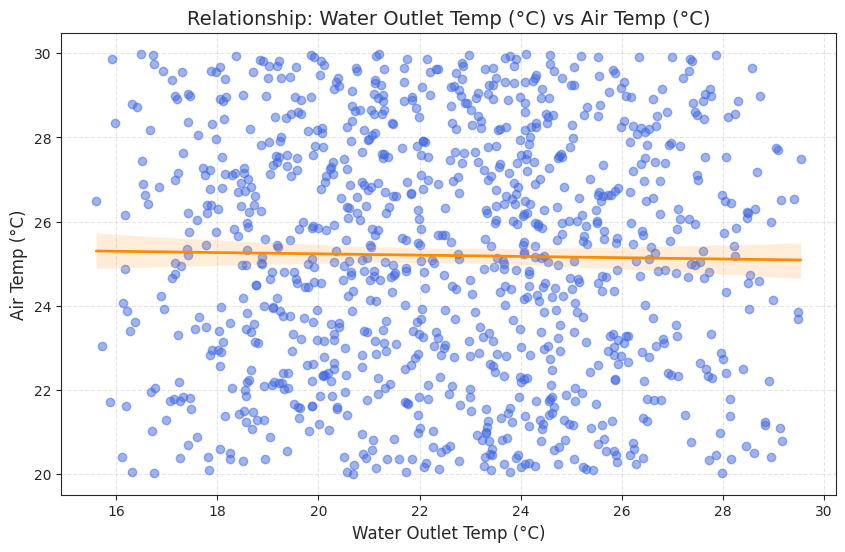

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

if 'df_real' in locals() or 'df_real' in globals():
    # Dynamically locate the exact column names
    columns = df_real.columns
    outlet_col = [col for col in columns if 'water' in col.lower() and 'outlet' in col.lower()][0]
    air_temp_col = [col for col in columns if 'air' in col.lower() and 'temp' in col.lower()][0]

    # Filter data and drop missing values
    analysis_data = df_real[[outlet_col, air_temp_col]].dropna()

    # Calculate Covariance and Correlation
    covariance = analysis_data.cov().iloc[0, 1]
    correlation = analysis_data.corr().iloc[0, 1]

    print(f"Covariance between Water Outlet Temp and Air Temp: {covariance:.4f}")
    print(f"Correlation (Pearson's r) between Water Outlet Temp and Air Temp: {correlation:.4f}")

    # Generate Scatter Plot
    plt.figure(figsize=(10, 6))
    sns.regplot(
        data=analysis_data,
        x=outlet_col,
        y=air_temp_col,
        scatter_kws={'alpha': 0.5, 'color': 'royalblue'},
        line_kws={'color': 'darkorange', 'linewidth': 2}
    )
    plt.title(f'Relationship: {outlet_col} vs {air_temp_col}', fontsize=14)
    plt.xlabel(outlet_col, fontsize=12)
    plt.ylabel(air_temp_col, fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()
else:
    print("Dataset not found. Please verify that the dataset is successfully loaded.")

The statistics confirm that there's cooling taking place because the water temperature reduces from an inlet mean of 30(°C) - (hot water entering the cooling tower std dev 2.83) to an outlet 22(°C) - (the cooled water leaving the tower std dev 3.22) with the mean air temperature being 25(°C) - (ambient air temperature std dev 2.83.)  
The drop in temperature of the water quantitatively confirms heat rejection and cooling performance within the tower.

The covariance and correlation between Water Outlet Temp (°C) and Air Temp (°C) have been successfully calculated:

Covariance: -0.1591,
Correlation (Pearson's r): -0.0171
Interpretation:
Very Weak Correlation: A correlation coefficient of approximately -0.0171 is extremely close to 0. This suggests that there is no linear correlation between the Water outlet Temperature and the Air Temperature in this dataset.
This is confirmed and observed on the plot, because the data points are scattered uniformly across the plane, and the red trend is nearly flat (horizontal), confirming that there's virtually no linear correlation  between the two variables in the dataset. This analysis suggests that other operating variables such as water flow rate, fan speed or humidity play an active role in driving the outlet temperature variations in this system which is very true.

### Formulating a Mathematical Equation for Water Outlet Temperature
**A Thermodynamic/Empirical Perspective:** Cooling towers work on the principle of evaporative cooling, where the limit of cooling is defined by the wet-bulb temperature (which itself is a function of Air Temperature and Outdoor Humidity).

To construct an empirical mathematical equation of the form:
$$\text{Water Outlet Temp} = \beta_0 + (\beta_1 \times \text{Water Inlet Temp}) + (\beta_2 \times \text{Air Temp}) + (\beta_3 \times \text{Outdoor Humidity})$$

We will fit a Multiple Linear Regression model using `scikit-learn` on the dataset `df_real` to determine the exact coefficients ($\beta_0, \beta_1, \beta_2, \beta_3$).

In [40]:
from sklearn.linear_model import LinearRegression
import numpy as np

if 'df_real' in locals() or 'df_real' in globals():
    # Dynamically locate the exact column names
    columns = df_real.columns
    inlet_col = [col for col in columns if 'water' in col.lower() and 'inlet' in col.lower()][0]
    outlet_col = [col for col in columns if 'water' in col.lower() and 'outlet' in col.lower()][0]
    air_temp_col = [col for col in columns if 'air' in col.lower() and 'temp' in col.lower()][0]
    humidity_col = [col for col in columns if 'humidity' in col.lower()][0]

    # Extract features and target variable, dropping missing rows
    data_subset = df_real[[outlet_col, inlet_col, air_temp_col, humidity_col]].dropna()

    X = data_subset[[inlet_col, air_temp_col, humidity_col]]
    y = data_subset[outlet_col]

    # Fit Linear Regression Model
    model = LinearRegression()
    model.fit(X, y)

    # Retrieve intercept and coefficients
    beta_0 = model.intercept_
    beta_1, beta_2, beta_3 = model.coef_
    r_sq = model.score(X, y)

    print("--- Fitted Mathematical Equation coefficients ---")
    print(f"Intercept (Beta 0): {beta_0:.4f}")
    print(f"Coefficient for Water Inlet Temp (Beta 1): {beta_1:.4f}")
    print(f"Coefficient for Air Temp (Beta 2): {beta_2:.4f}")
    print(f"Coefficient for Outdoor Humidity (Beta 3): {beta_3:.4f}")
    print(f"Model R-squared: {r_sq:.4f}\n")

    print("Represented Equation:")
    print(f"Water Outlet Temp = {beta_0:.4f} + ({beta_1:.4f} * Water Inlet Temp) + ({beta_2:.4f} * Air Temp) + ({beta_3:.4f} * Outdoor Humidity)")
else:
    print("Dataset not found. Please verify that the dataset is successfully loaded.")

--- Fitted Mathematical Equation coefficients ---
Intercept (Beta 0): -8.4824
Coefficient for Water Inlet Temp (Beta 1): 1.0191
Coefficient for Air Temp (Beta 2): 0.0058
Coefficient for Outdoor Humidity (Beta 3): 0.0046
Model R-squared: 0.8018

Represented Equation:
Water Outlet Temp = -8.4824 + (1.0191 * Water Inlet Temp) + (0.0058 * Air Temp) + (0.0046 * Outdoor Humidity)
